In [1]:
import pandas as pd

In [2]:
df=pd.read_csv ("Data/E02526.csv")

In [3]:
df.shape

(380, 132)

In [4]:
df.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


In [5]:
df.columns

Index(['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR',
       'HTHG', 'HTAG',
       ...
       'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA',
       'AvgCAHH', 'AvgCAHA', 'BFECAHH', 'BFECAHA'],
      dtype='str', length=132)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Columns: 132 entries, Div to BFECAHA
dtypes: float64(108), int64(16), str(8)
memory usage: 392.0 KB


In [7]:
matches = df[['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR']].copy()
matches.shape

(380, 6)

In [8]:
matches['FTR'].value_counts()

FTR
H    162
A    114
D    104
Name: count, dtype: int64

In [9]:
matches['FTR'].value_counts(normalize=True)

FTR
H    0.426316
A    0.300000
D    0.273684
Name: proportion, dtype: float64

In [10]:
matches['Date'] = pd.to_datetime(matches['Date'], dayfirst=True)
matches = matches.sort_values('Date').reset_index(drop=True)
matches.dtypes

Date        datetime64[us]
HomeTeam               str
AwayTeam               str
FTHG                 int64
FTAG                 int64
FTR                    str
dtype: object

In [11]:
matches['Date'].min(), matches['Date'].max()

(Timestamp('2025-08-15 00:00:00'), Timestamp('2026-05-24 00:00:00'))

In [12]:
import glob

def load_season(path):
    d = pd.read_csv(path, encoding='latin-1')
    d = d[['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'B365H', 'B365D', 'B365A']].dropna()
    d['Date'] = pd.to_datetime(d['Date'], dayfirst=True)
    d['Season'] = path[-8:-4]
    return d

files = sorted(glob.glob('data/E0*.csv'))
print(files)

['data\\E01617.csv', 'data\\E01718.csv', 'data\\E01819.csv', 'data\\E01920.csv', 'data\\E02021.csv', 'data\\E02122.csv', 'data\\E02223.csv', 'data\\E02324.csv', 'data\\E02425.csv', 'data\\E02526.csv']


In [13]:
matches = pd.concat([load_season(f) for f in files], ignore_index=True)
matches = matches.sort_values('Date').reset_index(drop=True)
matches.shape

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21432\2699018460.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['Date'] = pd.to_datetime(d['Date'], dayfirst=True)


(3800, 10)

In [14]:
matches.groupby('Season')['Date'].agg(['min', 'max'])

,min,max
Season,,
1617,2016-08-13,2017-05-21
1718,2017-08-11,2018-05-13
1819,2018-08-10,2019-05-12
1920,2019-08-09,2020-07-26
2021,2020-09-12,2021-05-23
2122,2021-08-13,2022-05-22
2223,2022-08-05,2023-05-28
2324,2023-08-11,2024-05-19
2425,2024-08-16,2025-05-25


In [15]:
matches.groupby('Season').size()

Season
1617    380
1718    380
1819    380
1920    380
2021    380
2122    380
2223    380
2324    380
2425    380
2526    380
dtype: int64

In [16]:
sorted(matches['HomeTeam'].unique())

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Cardiff',
 'Chelsea',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Huddersfield',
 'Hull',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Middlesbrough',
 'Newcastle',
 'Norwich',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Stoke',
 'Sunderland',
 'Swansea',
 'Tottenham',
 'Watford',
 'West Brom',
 'West Ham',
 'Wolves']

In [17]:
matches['MatchId'] = matches.index
matches['Points_H'] = matches['FTR'].map({'H': 3, 'D': 1, 'A': 0})
matches['Points_A'] = matches['FTR'].map({'H': 0, 'D': 1, 'A': 3})

In [18]:
home = matches[['MatchId', 'Date', 'HomeTeam', 'FTHG', 'FTAG', 'Points_H']].copy()
home.columns = ['MatchId', 'Date', 'Team', 'GF', 'GA', 'Pts']
home['IsHome'] = 1

away = matches[['MatchId', 'Date', 'AwayTeam', 'FTAG', 'FTHG', 'Points_A']].copy()
away.columns = ['MatchId', 'Date', 'Team', 'GF', 'GA', 'Pts']
away['IsHome'] = 0

long = pd.concat([home, away]).sort_values(['Team', 'Date', 'MatchId']).reset_index(drop=True)
long.shape

(7600, 7)

In [19]:
long[long['Team'] == 'Arsenal'].head(8)

,MatchId,Date,Team,GF,GA,Pts,IsHome
0,7,2016-08-14,Arsenal,3,4,0,1
1,16,2016-08-20,Arsenal,0,0,1,0
2,21,2016-08-27,Arsenal,3,1,3,0
3,30,2016-09-10,Arsenal,2,1,3,1
4,42,2016-09-17,Arsenal,4,1,3,0
5,55,2016-09-24,Arsenal,3,0,3,1
6,68,2016-10-02,Arsenal,1,0,3,0
7,76,2016-10-15,Arsenal,3,2,3,1


In [20]:
for col in ['GF', 'GA', 'Pts']:
    long[col + '_avg5'] = long.groupby('Team')[col].transform(
        lambda s: s.shift(1).rolling(5, min_periods=5).mean()
    )

In [21]:
long[long['Team'] == 'Arsenal'].head(8)

,MatchId,Date,Team,GF,GA,Pts,IsHome,GF_avg5,GA_avg5,Pts_avg5
0,7,2016-08-14,Arsenal,3,4,0,1,NaN,NaN,NaN
1,16,2016-08-20,Arsenal,0,0,1,0,NaN,NaN,NaN
2,21,2016-08-27,Arsenal,3,1,3,0,NaN,NaN,NaN
3,30,2016-09-10,Arsenal,2,1,3,1,NaN,NaN,NaN
4,42,2016-09-17,Arsenal,4,1,3,0,NaN,NaN,NaN
5,55,2016-09-24,Arsenal,3,0,3,1,2.4,1.4,2.0
6,68,2016-10-02,Arsenal,1,0,3,0,2.4,0.6,2.6
7,76,2016-10-15,Arsenal,3,2,3,1,2.6,0.6,3.0


In [22]:
feats = long[['MatchId', 'IsHome', 'GF_avg5', 'GA_avg5', 'Pts_avg5']]

home_f = feats[feats['IsHome'] == 1].drop(columns='IsHome').add_prefix('H_').rename(columns={'H_MatchId': 'MatchId'})
away_f = feats[feats['IsHome'] == 0].drop(columns='IsHome').add_prefix('A_').rename(columns={'A_MatchId': 'MatchId'})

data = matches.merge(home_f, on='MatchId').merge(away_f, on='MatchId')
data.shape

(3800, 19)

In [23]:
data = data.dropna().reset_index(drop=True)
data.shape

(3681, 19)

In [24]:
data[['Date', 'HomeTeam', 'AwayTeam', 'FTR', 'H_GF_avg5', 'H_Pts_avg5', 'A_GF_avg5', 'A_Pts_avg5']].head()

,Date,HomeTeam,AwayTeam,FTR,H_GF_avg5,H_Pts_avg5,A_GF_avg5,A_Pts_avg5
0,2016-09-24,Swansea,Man City,A,0.8,0.8,3.0,3.0
1,2016-09-24,Stoke,West Brom,D,0.6,0.2,1.2,1.4
2,2016-09-24,Middlesbrough,Tottenham,A,1.0,1.0,1.6,2.2
3,2016-09-24,Sunderland,Crystal Palace,A,0.6,0.2,1.4,1.4
4,2016-09-24,Liverpool,Hull,H,2.2,2.0,1.2,1.4


In [25]:
features = ['H_GF_avg5', 'H_GA_avg5', 'H_Pts_avg5',
            'A_GF_avg5', 'A_GA_avg5', 'A_Pts_avg5']

train = data[data['Season'] < '2425']
test = data[data['Season'] >= '2425']

X_train, y_train = train[features], train['FTR']
X_test, y_test = test[features], test['FTR']

print(X_train.shape, X_test.shape)

(2926, 6) (755, 6)


In [26]:
from sklearn.metrics import accuracy_score, log_loss

baseline_acc = (y_test == 'H').mean()
baseline_acc

np.float64(0.4185430463576159)

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)

print('accuracy:', accuracy_score(y_test, pred))
print('log loss:', log_loss(y_test, proba, labels=model.classes_))

accuracy: 0.4860927152317881
log loss: 1.048732865522405


In [28]:
pd.Series(pred).value_counts()

H    524
A    231
Name: count, dtype: int64

In [29]:
from sklearn.metrics import confusion_matrix, classification_report

print(model.classes_)
print(confusion_matrix(y_test, pred, labels=model.classes_))
print(classification_report(y_test, pred, zero_division=0))

['A' 'D' 'H']
[[117   0 128]
 [ 48   0 146]
 [ 66   0 250]]
              precision    recall  f1-score   support

           A       0.51      0.48      0.49       245
           D       0.00      0.00      0.00       194
           H       0.48      0.79      0.60       316

    accuracy                           0.49       755
   macro avg       0.33      0.42      0.36       755
weighted avg       0.36      0.49      0.41       755



In [30]:
import numpy as np

priors = y_train.value_counts(normalize=True).reindex(model.classes_)
naive_proba = np.tile(priors.values, (len(y_test), 1))
log_loss(y_test, naive_proba, labels=model.classes_)

1.0823842923226672

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)

print('accuracy:', accuracy_score(y_test, rf_pred))
print('log loss:', log_loss(y_test, rf_proba, labels=rf.classes_))

accuracy: 0.4688741721854305
log loss: 1.0733102111916668


In [32]:
odds = test[['B365A', 'B365D', 'B365H']]
imp = 1 / odds
book_proba = imp.div(imp.sum(axis=1), axis=0).values
book_pred = np.array(['A', 'D', 'H'])[book_proba.argmax(axis=1)]

In [33]:
print('bookmaker accuracy:', accuracy_score(y_test, book_pred))
print('bookmaker log loss:', log_loss(y_test, book_proba, labels=['A', 'D', 'H']))

bookmaker accuracy: 0.5165562913907285
bookmaker log loss: 0.9949707136531014


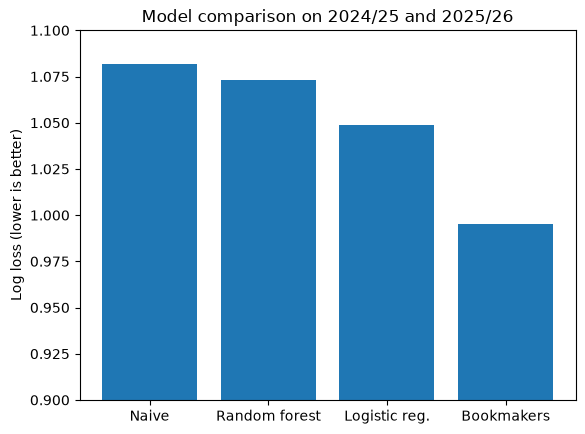

In [34]:
import matplotlib.pyplot as plt

names = ['Naive', 'Random forest', 'Logistic reg.', 'Bookmakers']
losses = [1.082, 1.073, 1.049, 0.995]

plt.bar(names, losses)
plt.ylim(0.9, 1.1)
plt.ylabel('Log loss (lower is better)')
plt.title('Model comparison on 2024/25 and 2025/26')
plt.savefig('log_loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

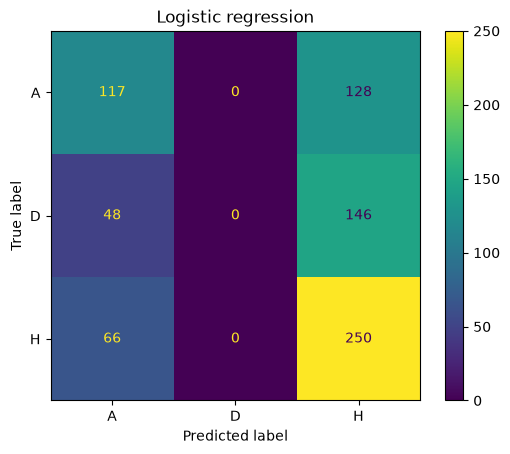

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['A', 'D', 'H'])
plt.title('Logistic regression')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

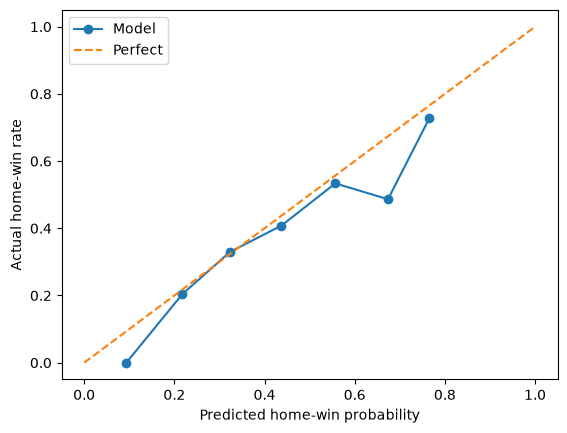

In [36]:
from sklearn.calibration import calibration_curve

idx = list(model.classes_).index('H')
frac, mean_pred = calibration_curve(y_test == 'H', proba[:, idx], n_bins=8)

plt.plot(mean_pred, frac, marker='o', label='Model')
plt.plot([0, 1], [0, 1], '--', label='Perfect')
plt.xlabel('Predicted home-win probability')
plt.ylabel('Actual home-win rate')
plt.legend()
plt.savefig('calibration.png', dpi=150, bbox_inches='tight')
plt.show()

In [37]:
probs = pd.DataFrame(proba, columns=model.classes_, index=test.index).round(3)
out = test[['Date', 'HomeTeam', 'AwayTeam', 'FTR']].join(probs)
out.head(10)

,Date,HomeTeam,AwayTeam,FTR,A,D,H
2926,2024-08-16,Man United,Fulham,H,0.258,0.237,0.505
2927,2024-08-17,West Ham,Aston Villa,A,0.323,0.255,0.422
2928,2024-08-17,Nott'm Forest,Bournemouth,D,0.306,0.247,0.448
2929,2024-08-17,Newcastle,Southampton,H,0.101,0.142,0.757
2930,2024-08-17,Everton,Brighton,A,0.177,0.215,0.608
2931,2024-08-17,Arsenal,Wolves,H,0.063,0.134,0.803
2932,2024-08-18,Brentford,Crystal Palace,H,0.556,0.205,0.239
2933,2024-08-18,Chelsea,Man City,A,0.377,0.217,0.406
2934,2024-08-19,Leicester,Tottenham,D,0.319,0.247,0.434
2935,2024-08-24,Aston Villa,Arsenal,A,0.514,0.244,0.242


In [38]:
def predict_match(home, away):
    form = long.groupby('Team').tail(5).groupby('Team')[['GF', 'GA', 'Pts']].mean()
    h, a = form.loc[home], form.loc[away]
    x = pd.DataFrame([[h.GF, h.GA, h.Pts, a.GF, a.GA, a.Pts]], columns=features)
    p = model.predict_proba(x)[0]
    return dict(zip(model.classes_, p.round(3)))

predict_match('Arsenal', "Nott'm Forest")

{'A': np.float64(0.306), 'D': np.float64(0.219), 'H': np.float64(0.475)}

In [39]:
cur = load_season('Data/Current/E0.csv')
cur.shape

(90, 10)

In [40]:
cur['Date'].max(), cur['Season'].unique()
sorted(cur['HomeTeam'].unique())

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Chelsea',
 'Coventry',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Hull',
 'Ipswich',
 'Leeds',
 'Liverpool',
 'Man City',
 'Man United',
 'Newcastle',
 "Nott'm Forest",
 'Sunderland',
 'Tottenham']

In [41]:
cols = ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR']
allm = pd.concat([matches[cols], cur[cols]], ignore_index=True)
allm = allm.sort_values('Date').reset_index(drop=True)
allm['Pts_H'] = allm['FTR'].map({'H': 3, 'D': 1, 'A': 0})
allm['Pts_A'] = allm['FTR'].map({'H': 0, 'D': 1, 'A': 3})

In [42]:
h = allm[['Date', 'HomeTeam', 'FTHG', 'FTAG', 'Pts_H']].copy()
h.columns = ['Date', 'Team', 'GF', 'GA', 'Pts']
a = allm[['Date', 'AwayTeam', 'FTAG', 'FTHG', 'Pts_A']].copy()
a.columns = ['Date', 'Team', 'GF', 'GA', 'Pts']

form_long = pd.concat([h, a]).sort_values(['Team', 'Date']).reset_index(drop=True)
form_long.shape

(7780, 5)

In [43]:
def predict_match(home, away):
    form = form_long.groupby('Team').tail(5).groupby('Team')[['GF', 'GA', 'Pts']].mean()
    hf, af = form.loc[home], form.loc[away]
    x = pd.DataFrame([[hf.GF, hf.GA, hf.Pts, af.GF, af.GA, af.Pts]], columns=features)
    p = model.predict_proba(x)[0]
    return dict(zip(model.classes_, p.round(3)))

In [44]:
form_long[form_long['Team'] == 'Arsenal'].tail(5)

,Date,Team,GF,GA,Pts
384,2026-09-19,Arsenal,0,3,0
385,2026-10-10,Arsenal,2,1,3
386,2026-10-18,Arsenal,1,0,3
387,2026-10-24,Arsenal,2,0,3
388,2026-11-01,Arsenal,1,0,3


In [45]:
predict_match('Newcastle', 'Arsenal')

{'A': np.float64(0.36), 'D': np.float64(0.258), 'H': np.float64(0.382)}

In [46]:
predict_match('Arsenal', 'Hull')

{'A': np.float64(0.229), 'D': np.float64(0.23), 'H': np.float64(0.541)}

In [47]:
form_long[form_long['Team'] == 'Man City'].tail(5)

,Date,Team,GF,GA,Pts
4728,2026-09-20,Man City,5,3,3
4729,2026-10-11,Man City,3,0,3
4730,2026-10-17,Man City,3,2,3
4731,2026-10-24,Man City,1,2,0
4732,2026-10-31,Man City,0,1,0


In [48]:

form_long[form_long['Team'] == 'Fulham'].tail(5)

,Date,Team,GF,GA,Pts
3277,2026-09-20,Fulham,1,1,1
3278,2026-10-10,Fulham,1,2,0
3279,2026-10-17,Fulham,1,0,3
3280,2026-10-24,Fulham,1,0,3
3281,2026-10-31,Fulham,1,1,1


In [49]:
predict_match('Man City', 'Fulham')

{'A': np.float64(0.217), 'D': np.float64(0.23), 'H': np.float64(0.552)}

In [50]:
predict_match('Ipswich', 'Bournemouth')

{'A': np.float64(0.366), 'D': np.float64(0.239), 'H': np.float64(0.395)}